# 🏢 Enterprise Cluster Telemetry: Server Machine Dataset (SMD / KDD 2019)
## High-Dimensional Multivariate Anomaly Detection, Resource Contention Spikes & Node Failures

### 1. Incident Background & Multi-Sensor Structure
In large-scale cloud services and distributed data centers, thousands of compute nodes operate concurrently. When software bugs, resource contention, memory leaks, or network hardware failures occur, the underlying machine telemetry exhibits sudden, localized deviations across subsets of metrics.

The **Server Machine Dataset (SMD)** was collected by Tsinghua University and a large internet company over a 5-week continuous observation period across 28 server machines (`machine-1-1` to `machine-3-11`). It is one of the most widely cited benchmarks in computer science for evaluating multivariate anomaly detection, deep generative models (VAEs/GANs), and graph neural networks.

This notebook examines **`machine-1-1`**, consisting of **28,479 continuous 1-minute observations across 38 metrics** (CPU utilization, memory usage, disk I/O, network ingress/egress) paired with **binary ground-truth anomaly annotations (`y = 1`)** verified by human domain engineers.

### 2. Target Variables ($y$)
* **`label`**: Ground truth binary anomaly indicator (`y = 1` indicates an active anomaly/breakdown window).
* **38 Telemetry Dimensions (`dim_0` to `dim_37`)**: Continuous operational metrics showcasing abrupt spikes, resource exhaustion plateaus, and structural variance changes.


### 📚 Academic Citations & Benchmark Lineage
* **Primary Paper:** Su, Y., Zhao, Y., Niu, C., Liu, R., Sun, W., & Pei, D. (2019). *"Robust Anomaly Detection for Multivariate Time Series through Stochastic Recurrent Neural Network."* In *Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining (KDD '19)*, pp. 2828–2837.
* **Benchmark Context:** Standard gold-benchmark for multivariate time-series anomaly detection and root-cause localization (1,000+ academic citations across KDD, NeurIPS, PVLDB, and ICML).
* **BibTeX Citation:**
```bibtex
@inproceedings{su2019robust,
  title={Robust Anomaly Detection for Multivariate Time Series through Stochastic Recurrent Neural Network},
  author={Su, Ya and Zhao, Youjian and Niu, Chenhao and Liu, Rong and Sun, Wei and Pei, Dan},
  booktitle={Proceedings of the 25th ACM SIGKDD International Conference on Knowledge Discovery \& Data Mining (KDD '19)},
  pages={2828--2837},
  year={2019}
}
```

In [2]:
import os
import requests
import io
import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
os.makedirs('data', exist_ok=True)
print("Environment initialized successfully!")

/opt/anaconda3/envs/sermos/lib/python3.11/site-packages/requests/__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


Environment initialized successfully!


### 3. Data Ingestion & Local Caching

In [3]:
def fetch_smd_telemetry(machine_id='machine-1-1', cache_dir='data'):
    cache_data_path = os.path.join(cache_dir, f'smd_{machine_id.replace("-", "_")}_raw.csv')
    
    if os.path.exists(cache_data_path):
        print(f"Loading cached SMD telemetry from: {cache_data_path}")
        df = pd.read_csv(cache_data_path)
        return df
    
    print(f"Downloading Server Machine Dataset ({machine_id}) from official OmniAnomaly repository...")
    url_data = f'https://raw.githubusercontent.com/NetManAIOps/OmniAnomaly/master/ServerMachineDataset/test/{machine_id}.txt'
    url_label = f'https://raw.githubusercontent.com/NetManAIOps/OmniAnomaly/master/ServerMachineDataset/test_label/{machine_id}.txt'
    
    r_data = requests.get(url_data, timeout=30)
    r_data.raise_for_status()
    r_label = requests.get(url_label, timeout=30)
    r_label.raise_for_status()
    
    df_data = pd.read_csv(io.StringIO(r_data.text), sep=',', header=None)
    df_data.columns = [f'dim_{i}' for i in range(df_data.shape[1])]
    
    df_label = pd.read_csv(io.StringIO(r_label.text), header=None, names=['label'])
    
    df_merged = pd.concat([df_data, df_label], axis=1)
    
    # Generate continuous timestamp starting at arbitrary baseline
    base_time = pd.to_datetime('2019-01-01 00:00:00')
    df_merged['timestamp'] = [base_time + datetime.timedelta(minutes=i) for i in range(len(df_merged))]
    
    df_merged.to_csv(cache_data_path, index=False)
    print(f"Downloaded and cached {len(df_merged):,} observations across {df_data.shape[1]} metrics.")
    return df_merged

df_smd = fetch_smd_telemetry()
df_smd.head()

Loading cached SMD telemetry from: data/smd_machine_1_1_raw.csv


,dim_0,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7,dim_8,dim_9,...,dim_30,dim_31,dim_32,dim_33,dim_34,dim_35,dim_36,dim_37,label,timestamp
0,0.075269,0.065678,0.070234,0.074332,0.0,0.933333,0.274011,0.0,0.031081,0.000000,...,0.068036,0.048893,0.000386,0.000034,0.064432,0.064500,0.0,0.0,0,2019-01-01 00:00:00
1,0.086022,0.080508,0.075808,0.076655,0.0,0.930769,0.274953,0.0,0.031081,0.000122,...,0.070020,0.050437,0.000386,0.000022,0.065228,0.065224,0.0,0.0,0,2019-01-01 00:01:00
2,0.075269,0.064619,0.071349,0.074332,0.0,0.928205,0.274953,0.0,0.030940,0.000366,...,0.069684,0.055069,0.000386,0.000045,0.067111,0.067178,0.0,0.0,0,2019-01-01 00:02:00
3,0.086022,0.048729,0.063545,0.070848,0.0,0.928205,0.273070,0.0,0.027250,0.000244,...,0.073253,0.051467,0.000000,0.000034,0.066676,0.066744,0.0,0.0,0,2019-01-01 00:03:00
4,0.086022,0.051907,0.062430,0.070848,0.0,0.933333,0.274011,0.0,0.030940,0.000244,...,0.070932,0.051467,0.000386,0.000022,0.066604,0.066671,0.0,0.0,0,2019-01-01 00:04:00


### 4. Multivariate Feature Engineering & Anomaly Identification

In [3]:
df_smd_proc = df_smd.copy()

# 1. Identify which metrics exhibit the most violent shift during label == 1 vs label == 0
dim_cols = [c for c in df_smd_proc.columns if c.startswith('dim_')]
mean_normal = df_smd_proc[df_smd_proc['label'] == 0][dim_cols].mean()
mean_anomaly = df_smd_proc[df_smd_proc['label'] == 1][dim_cols].mean()
std_normal = df_smd_proc[df_smd_proc['label'] == 0][dim_cols].std().replace(0, 1e-4)

# Standardized shift magnitude
z_shifts = (mean_anomaly - mean_normal) / std_normal
top_spike_dim = z_shifts.idxmax()
top_drop_dim = z_shifts.idxmin()

print(f"Total Observations:                      {len(df_smd_proc):,} (1-min steps)")
print(f"Ground-Truth Labeled Anomaly Periods:    {(df_smd_proc['label'] == 1).sum():,} ({df_smd_proc['label'].mean()*100:.2f}%)")
print(f"Sensor with Highest Upward Surge:        {top_spike_dim} (Standardized Shift: +{z_shifts[top_spike_dim]:.2f} sigma)")
print(f"Sensor with Highest Downward Plunge:     {top_drop_dim} (Standardized Shift: {z_shifts[top_drop_dim]:.2f} sigma)")

# 2. Rolling volatility & differences on top surge metric
df_smd_proc[f'{top_spike_dim}_velocity'] = df_smd_proc[top_spike_dim].diff()
df_smd_proc[f'{top_spike_dim}_rolling_std'] = df_smd_proc[top_spike_dim].rolling(30).std()

df_smd_proc.head()

Total Observations:                      28,479 (1-min steps)
Ground-Truth Labeled Anomaly Periods:    2,694 (9.46%)
Sensor with Highest Upward Surge:        dim_28 (Standardized Shift: +80.08 sigma)
Sensor with Highest Downward Plunge:     dim_22 (Standardized Shift: -0.36 sigma)


,dim_0,dim_1,dim_2,dim_3,dim_4,dim_5,dim_6,dim_7,dim_8,dim_9,...,dim_32,dim_33,dim_34,dim_35,dim_36,dim_37,label,timestamp,dim_28_velocity,dim_28_rolling_std
0,0.075269,0.065678,0.070234,0.074332,0.0,0.933333,0.274011,0.0,0.031081,0.000000,...,0.000386,0.000034,0.064432,0.064500,0.0,0.0,0,2019-01-01 00:00:00,NaN,NaN
1,0.086022,0.080508,0.075808,0.076655,0.0,0.930769,0.274953,0.0,0.031081,0.000122,...,0.000386,0.000022,0.065228,0.065224,0.0,0.0,0,2019-01-01 00:01:00,0.0,NaN
2,0.075269,0.064619,0.071349,0.074332,0.0,0.928205,0.274953,0.0,0.030940,0.000366,...,0.000386,0.000045,0.067111,0.067178,0.0,0.0,0,2019-01-01 00:02:00,0.0,NaN
3,0.086022,0.048729,0.063545,0.070848,0.0,0.928205,0.273070,0.0,0.027250,0.000244,...,0.000000,0.000034,0.066676,0.066744,0.0,0.0,0,2019-01-01 00:03:00,0.0,NaN
4,0.086022,0.051907,0.062430,0.070848,0.0,0.933333,0.274011,0.0,0.030940,0.000244,...,0.000386,0.000022,0.066604,0.066671,0.0,0.0,0,2019-01-01 00:04:00,0.0,NaN


### 5. Multi-Panel Timeline Visualizations of Server Anomaly Shocks

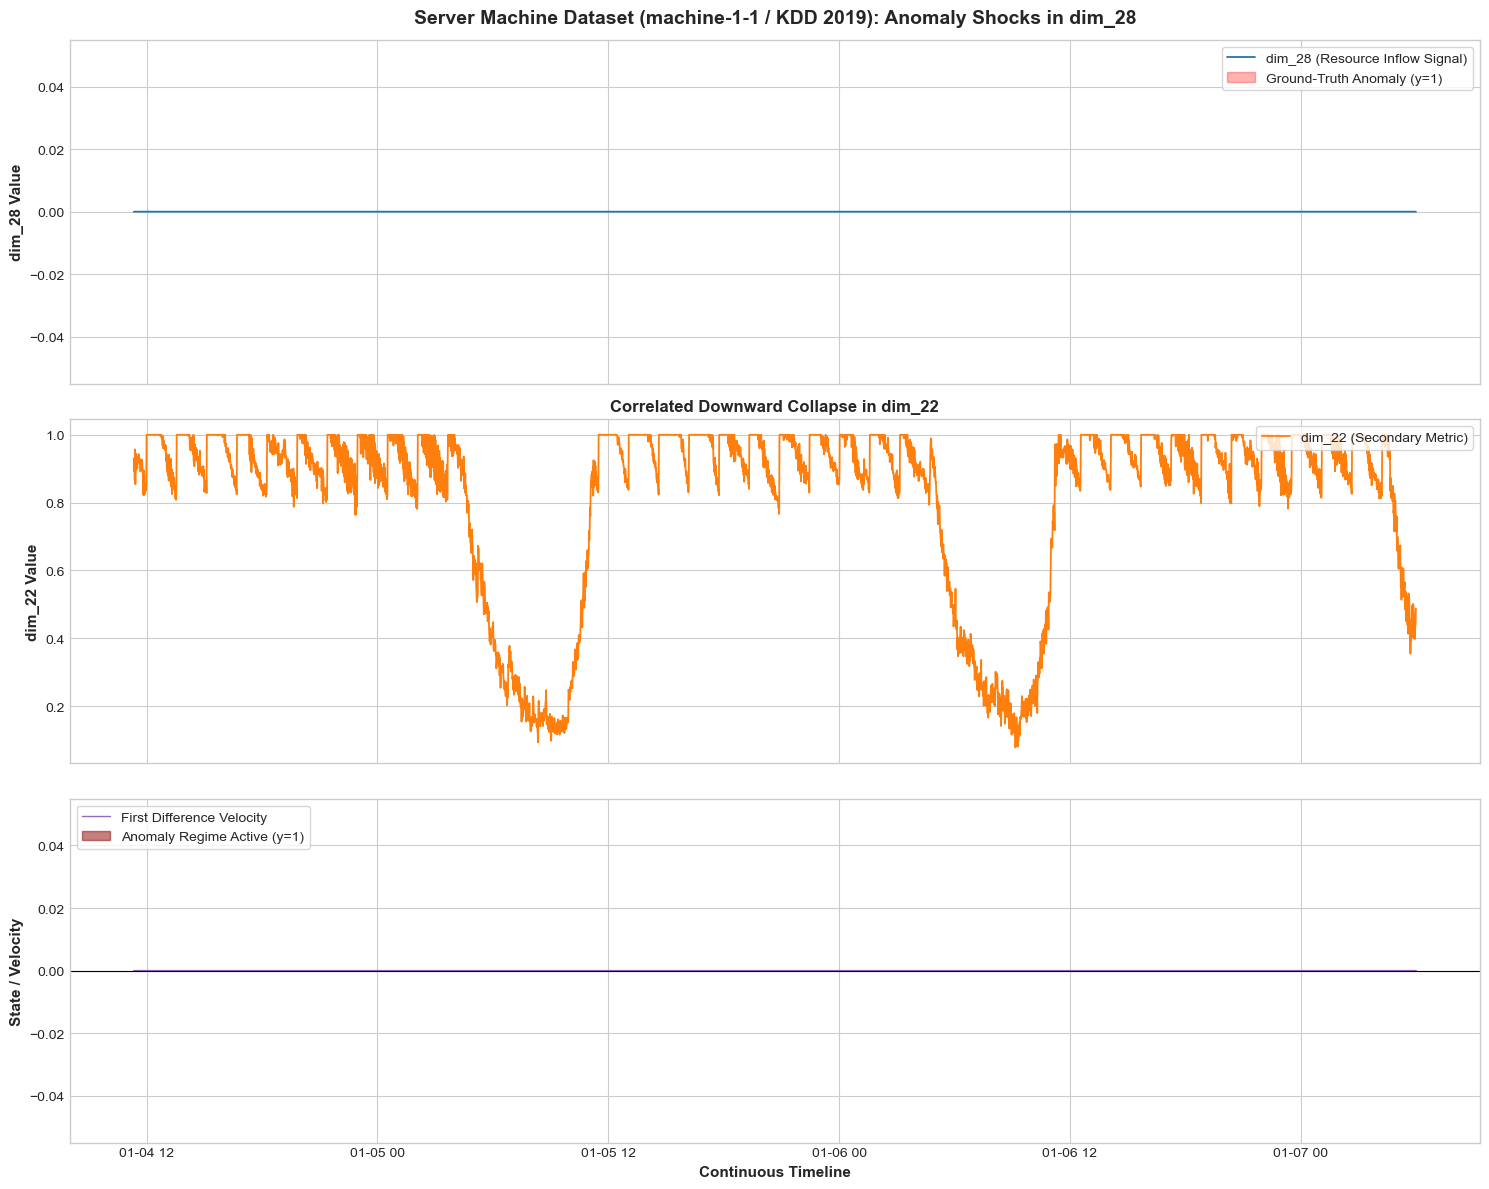

In [4]:
# Focus visualization on an active multi-day window with distinct anomaly episodes
sub_smd = df_smd_proc.iloc[5000:9000].copy()

fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

# 1. Primary Spike Metric with Anomaly Shading
ax1 = axes[0]
ax1.plot(sub_smd['timestamp'], sub_smd[top_spike_dim], color='#1f77b4', lw=1.3, label=f'{top_spike_dim} (Resource Inflow Signal)')
ax1.fill_between(sub_smd['timestamp'], sub_smd[top_spike_dim].min(), sub_smd[top_spike_dim].max(), 
                 where=(sub_smd['label'] == 1), color='red', alpha=0.3, step='mid', label='Ground-Truth Anomaly (y=1)')
ax1.set_title(f"Server Machine Dataset (machine-1-1 / KDD 2019): Anomaly Shocks in {top_spike_dim}", 
              fontsize=14, fontweight='bold', pad=12)
ax1.set_ylabel(f"{top_spike_dim} Value", fontsize=11, fontweight='bold')
ax1.legend(loc='upper right', frameon=True)

# 2. Secondary Drop Metric (Resource Starvation or Collapse)
ax2 = axes[1]
ax2.plot(sub_smd['timestamp'], sub_smd[top_drop_dim], color='#ff7f0e', lw=1.3, label=f'{top_drop_dim} (Secondary Metric)')
ax2.fill_between(sub_smd['timestamp'], sub_smd[top_drop_dim].min(), sub_smd[top_drop_dim].max(), 
                 where=(sub_smd['label'] == 1), color='red', alpha=0.25, step='mid')
ax2.set_ylabel(f"{top_drop_dim} Value", fontsize=11, fontweight='bold')
ax2.set_title(f"Correlated Downward Collapse in {top_drop_dim}", fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', frameon=True)

# 3. Ground Truth Breakdown Indicator and Spike Velocity
ax3 = axes[2]
ax3.plot(sub_smd['timestamp'], sub_smd[f'{top_spike_dim}_velocity'], color='#9467bd', lw=1.0, label='First Difference Velocity')
ax3.fill_between(sub_smd['timestamp'], 0, sub_smd['label'], color='darkred', alpha=0.5, step='mid', label='Anomaly Regime Active (y=1)')
ax3.axhline(0, color='black', lw=0.8)
ax3.set_ylabel("State / Velocity", fontsize=11, fontweight='bold')
ax3.set_xlabel("Continuous Timeline", fontsize=11, fontweight='bold')
ax3.legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.savefig('data/smd_machine1_1_timeline.png', dpi=300)
plt.show()

### 6. Processed Dataset Export

In [5]:
# Export clean processed dataset
out_path = 'data/smd_machine1_1_processed.csv'
df_smd_proc.to_csv(out_path, index=False)
print(f"Processed Server Machine Dataset successfully saved to: {out_path}")

Processed Server Machine Dataset successfully saved to: data/smd_machine1_1_processed.csv
